# Lazy vs Eager Learning: KNN vs Decision Tree
**Data Science Minor Project — Predictive Analysis**

## Project objectives
1. Understand the difference between lazy and eager learning.
2. Load and inspect a real classification dataset with at least 12 independent attributes.
3. Preprocess the data and create a reproducible stratified train/test split.
4. Train a K-Nearest Neighbors classifier as the lazy learner.
5. Train a Decision Tree classifier as the eager learner and visualize its learned structure.
6. Compare accuracy, macro precision, macro recall, macro F1, training time, and prediction time.
7. Interpret the results and document limitations.

**Research question:** How do KNN and Decision Tree compare on predictive performance and computational cost when evaluated on the same held-out records?

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## 2. Load the dataset

In [ ]:
df = pd.read_csv("wine_classification.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target_class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [4]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target_class
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


## 3. Exploratory data analysis

In [5]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Number of independent attributes:", df.shape[1] - 1)
print(df["target_class"].value_counts().sort_index())

Dataset shape: (178, 14)
Missing values: 0
Number of independent attributes: 13
target_class
0    59
1    71
2    48
Name: count, dtype: int64


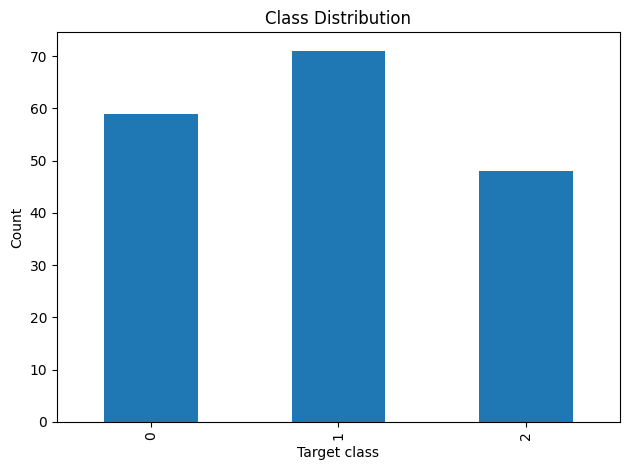

In [6]:
df["target_class"].value_counts().sort_index().plot(kind="bar", title="Class Distribution")
plt.xlabel("Target class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Preprocessing and train/test split

The target is `target_class`. All 13 chemical measurements are predictors. A stratified 75/25 split with a fixed random seed is shared by both models. KNN uses StandardScaler because distance-based methods are sensitive to feature scale. The Decision Tree is trained on the original feature scale because tree splits do not require standardization. The scaler is fitted only on training data through a Pipeline.

In [7]:
X = df.drop(columns=["target_class"])
y = df["target_class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 133
Testing records: 45


## 5. Define and train the models

In [8]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)

start = time.perf_counter()
knn_model.fit(X_train, y_train)
knn_training_time = time.perf_counter() - start

start = time.perf_counter()
tree_model.fit(X_train, y_train)
tree_training_time = time.perf_counter() - start

print("KNN training time:", knn_training_time)
print("Decision Tree training time:", tree_training_time)

KNN training time: 0.002895615999932488
Decision Tree training time: 0.0018892789998972148


## 6. Generate predictions and measure prediction time

In [9]:
# Warm-up calls are excluded from the repeated timing measurement.
knn_model.predict(X_test.iloc[:1])
tree_model.predict(X_test.iloc[:1])

repetitions = 30
start = time.perf_counter()
for _ in range(repetitions):
    knn_predictions = knn_model.predict(X_test)
knn_prediction_time = (time.perf_counter() - start) / repetitions

start = time.perf_counter()
for _ in range(repetitions):
    tree_predictions = tree_model.predict(X_test)
tree_prediction_time = (time.perf_counter() - start) / repetitions

## 7. Evaluate model performance

In [10]:
def evaluate_model(model_name, y_true, y_pred, training_time, prediction_time):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (Macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Training Time (s)": training_time,
        "Prediction Time / Batch (s)": prediction_time
    }

comparison = pd.DataFrame([
    evaluate_model("KNN (Lazy)", y_test, knn_predictions, knn_training_time, knn_prediction_time),
    evaluate_model("Decision Tree (Eager)", y_test, tree_predictions, tree_training_time, tree_prediction_time)
])
comparison

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),Training Time (s),Prediction Time / Batch (s)
0,KNN (Lazy),0.933333,0.929110,0.935185,0.931429,0.002896,0.001487
1,Decision Tree (Eager),0.955556,0.966667,0.950000,0.956469,0.001889,0.000369


In [11]:
comparison.to_csv("../results/model_comparison.csv", index=False)
print("KNN classification report")
print(classification_report(y_test, knn_predictions, target_names=["class_0", "class_1", "class_2"]))
print("Decision Tree classification report")
print(classification_report(y_test, tree_predictions, target_names=["class_0", "class_1", "class_2"]))

KNN classification report
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45

Decision Tree classification report
              precision    recall  f1-score   support

     class_0       1.00      0.93      0.97        15
     class_1       0.90      1.00      0.95        18
     class_2       1.00      0.92      0.96        12

    accuracy                           0.96        45
   macro avg       0.97      0.95      0.96        45
weighted avg       0.96      0.96      0.96        45



## 8. Confusion matrices

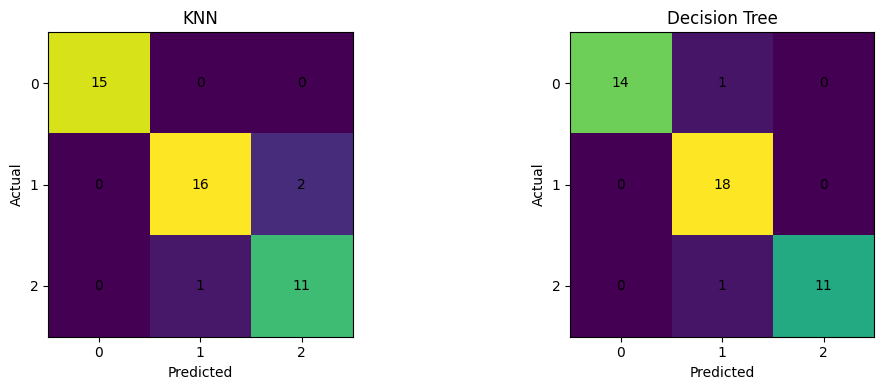

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, title, pred in [
    (axes[0], "KNN", knn_predictions),
    (axes[1], "Decision Tree", tree_predictions)
]:
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_xticks([0,1,2])
    ax.set_yticks([0,1,2])
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i,j], ha="center", va="center")
plt.tight_layout()
plt.show()

## 9. Visualize the Decision Tree using plot_tree

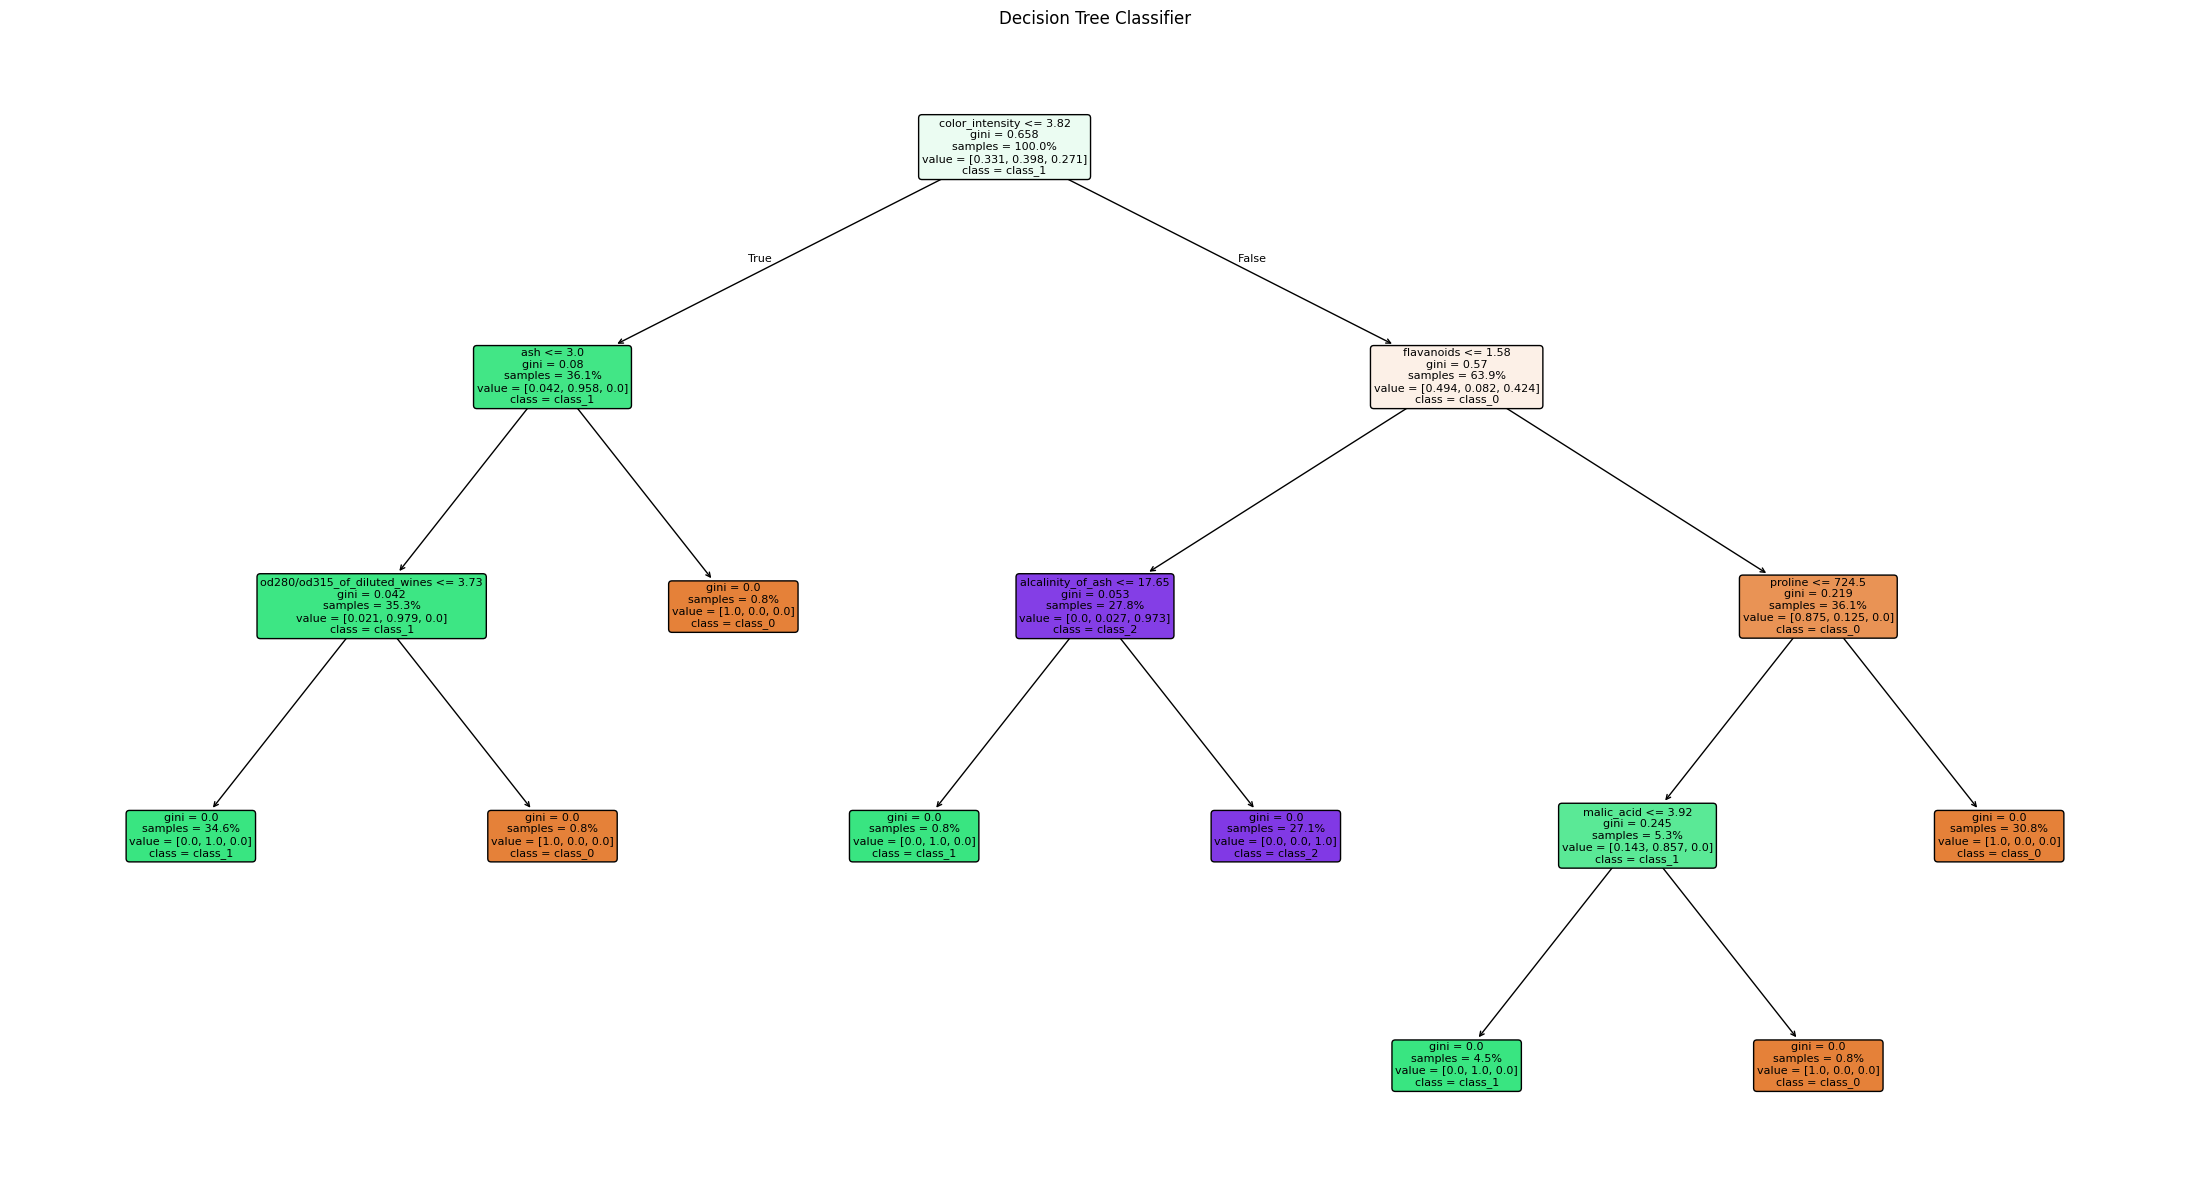

In [13]:
plt.figure(figsize=(22, 12))
plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=["class_0", "class_1", "class_2"],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=True,
    fontsize=8
)
plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

## 10. Compare the results

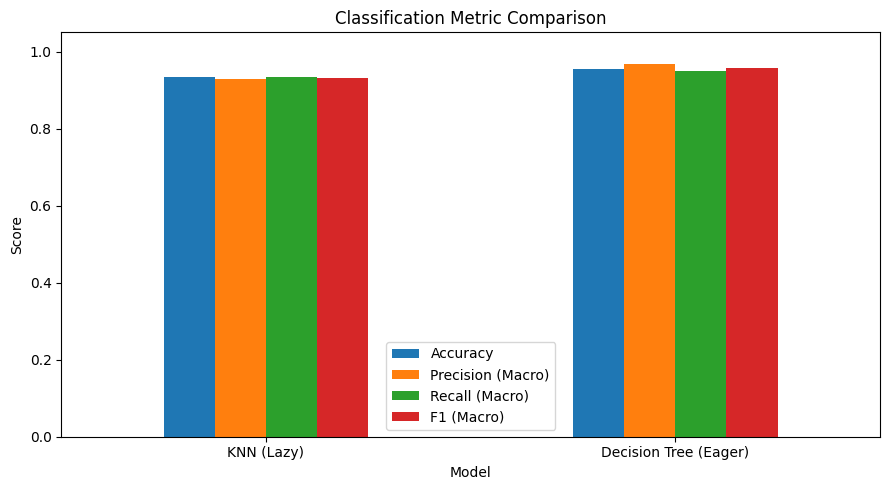

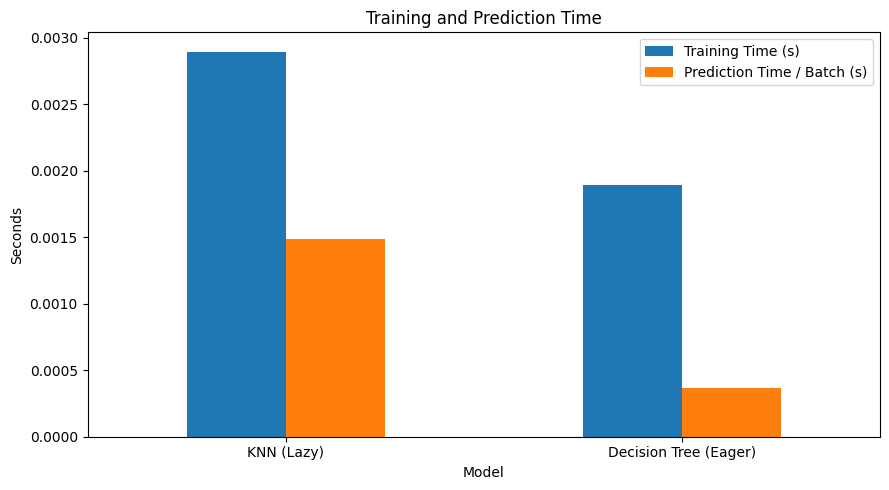

In [14]:
comparison.set_index("Model")[["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 (Macro)"]].plot(
    kind="bar", ylim=(0,1.05), figsize=(9,5), title="Classification Metric Comparison"
)
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison.set_index("Model")[["Training Time (s)", "Prediction Time / Batch (s)"]].plot(
    kind="bar", figsize=(9,5), title="Training and Prediction Time"
)
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Conclusion and limitations

The measured results describe these two fitted implementations on this dataset and split only. KNN is a lazy learner because it largely retains training examples and performs neighbour search at prediction time. Decision Tree is an eager learner because it constructs a set of decision rules during training and follows those rules during prediction.

Timing values depend on hardware, software versions, dataset size, and measurement method. The Wine dataset is small, so the timing differences may be very small and noisy. A broader study should repeat experiments across multiple dataset sizes and splits.